Computing the solution.
Plotting.


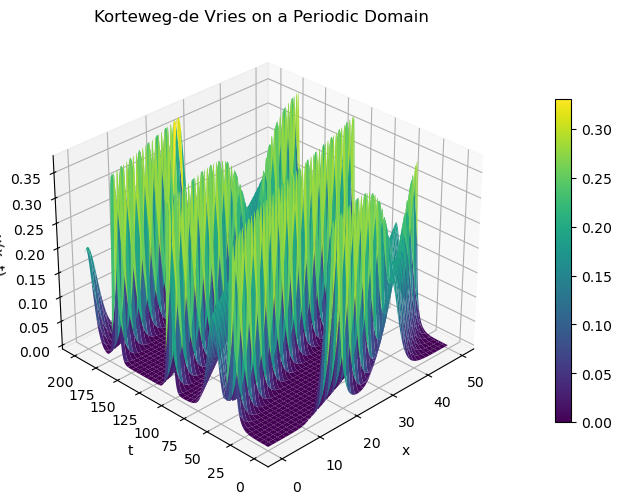

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
from scipy.fftpack import diff as psdiff
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

def kdv_exact(x, c):
    """Profile of the exact solution to the KdV for a single soliton on the real line."""
    return 0.5 * c * np.cosh(0.5 * np.sqrt(c) * x) ** (-2)

def kdv(u, t, L):
    """Differential equations for the KdV equation, discretized in x."""
    ux = psdiff(u, period=L)
    uxxx = psdiff(u, period=L, order=3)
    dudt = -6 * u * ux - uxxx
    return dudt

def kdv_solution(u0, t, L):
    """Solve the KdV on a periodic domain using a stiff solver (BDF).
    Returns an array with shape (len(t), len(u0))."""
    sol_ivp = solve_ivp(lambda tt, uu: kdv(uu, tt, L), (t[0], t[-1]), u0,
                        t_eval=t, method='BDF', rtol=1e-6, atol=1e-8)
    if not sol_ivp.success:
        raise RuntimeError(f"solve_ivp failed: {sol_ivp.message}")
    return sol_ivp.y.T

if __name__ == '__main__':
    # Domain and grid
    L = 50.0
    N = 256
    x = np.linspace(0, (1 - 1.0 / N) * L, N)

    # Initial condition: two solitons with different speeds (c values)
    u0 = kdv_exact(x - 0.33 * L, 0.75) + kdv_exact(x - 0.65 * L, 0.4)

    # Time grid
    T = 200
    t = np.linspace(0, T, 501)

    print("Computing the solution.")
    sol = kdv_solution(u0, t, L)

    print("Plotting.")

    # 3D surface plot
    X, Tm = np.meshgrid(x, t)
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection='3d')
    surf = ax.plot_surface(X, Tm, sol, cmap='viridis', linewidth=0, antialiased=True)
    fig.colorbar(surf, ax=ax, shrink=0.7, pad=0.1)
    ax.set_xlabel('x')
    ax.set_ylabel('t')
    ax.set_zlabel('u(x, t)')
    ax.set_title('Korteweg-de Vries on a Periodic Domain')
    ax.view_init(elev=30, azim=-135)
    plt.show()
